# EDA : Data visualisation and analysis 


**Import libraries**


In [1]:
import numpy as np 
import pandas as pd
import random 
import os  
import torch 
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText


In [2]:
plt.style.use('ggplot')

def seed_set(seed=50):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
seed_set()

In [3]:
from xyz2graph import MolGraph, to_networkx_graph, to_plotly_figure
from plotly.offline import init_notebook_mode, iplot
import networkx as nx


In [4]:
# Folder of the dataset (NOT the csv file)
DATA_DIR = r'C:\Users\pc\Downloads\champs-scalar-coupling'
CSV_PATH = os.path.join(DATA_DIR, 'structures.csv')
XYZ_DIR  = os.path.join(DATA_DIR, 'structures')  
COUPLING_DIR  = os.path.join(DATA_DIR , 'scalar_coupling_contributions') 

In [5]:
init_notebook_mode(connected=True)
structures = pd.read_csv(CSV_PATH)
mol_names = structures.molecule_name.unique()

In [6]:
print(structures.head())


      molecule_name  atom_index atom         x         y         z
0  dsgdb9nsd_000001           0    C -0.012698  1.085804  0.008001
1  dsgdb9nsd_000001           1    H  0.002150 -0.006031  0.001976
2  dsgdb9nsd_000001           2    H  1.011731  1.463751  0.000277
3  dsgdb9nsd_000001           3    H -0.540815  1.447527 -0.876644
4  dsgdb9nsd_000001           4    H -0.523814  1.437933  0.906397


In [7]:
structures.head(3).to_dict(orient='records')

[{'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 0,
  'atom': 'C',
  'x': -0.0126981359,
  'y': 1.0858041578,
  'z': 0.0080009957999999},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 1,
  'atom': 'H',
  'x': 0.002150416,
  'y': -0.0060313176,
  'z': 0.0019761204},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 2,
  'atom': 'H',
  'x': 1.0117308433,
  'y': 1.4637511618,
  'z': 0.0002765748}]

In [8]:
molecule_atoms = [
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 0,
        'atom': 'C',
        'x': -0.0126981359,
        'y': 1.0858041578,
        'z': 0.0080009957999999,
    },
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 1,
        'atom': 'H',
        'x': 0.002150416,
        'y': -0.0060313176,
        'z': 0.0019761204,
    },
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 2,
        'atom': 'H',
        'x': 1.0117308433,
        'y': 1.4637511618,
        'z': 0.0002765748,
    },
]

molecule_atoms

[{'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 0,
  'atom': 'C',
  'x': -0.0126981359,
  'y': 1.0858041578,
  'z': 0.0080009957999999},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 1,
  'atom': 'H',
  'x': 0.002150416,
  'y': -0.0060313176,
  'z': 0.0019761204},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 2,
  'atom': 'H',
  'x': 1.0117308433,
  'y': 1.4637511618,
  'z': 0.0002765748}]

In [9]:
mol_names = structures.molecule_name.unique()

In [10]:
def draw_random_mol():
    mol_name = random.choice(mol_names)
    mg = MolGraph()
    mg.read_xyz(os.path.join(XYZ_DIR, f'{mol_name}.xyz'))
    fig = to_plotly_figure(mg)
    iplot(fig)

def draw_random_networx_graph():
    mol_name = random.choice(mol_names)
    mg = MolGraph()
    mg.read_xyz(os.path.join(XYZ_DIR, f'{mol_name}.xyz'))
    G = to_networkx_graph(mg)
    print('Nodes:')
    print(list(G.nodes(data=True))[:5])
    print('Edges:')
    print(list(G.edges(data=True))[:5])
    nx.draw(G, with_labels=True)

In [11]:
draw_random_mol()

C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2953702703.py:5: DeprecationWarning: to_plotly_figure is deprecated and will be removed in version 4.0.0. Use MolGraph.to_plotly() instead.
  fig = to_plotly_figure(mg)


In [12]:
draw_random_mol()

C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2953702703.py:5: DeprecationWarning: to_plotly_figure is deprecated and will be removed in version 4.0.0. Use MolGraph.to_plotly() instead.
  fig = to_plotly_figure(mg)


C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2953702703.py:12: DeprecationWarning: to_networkx_graph is deprecated and will be removed in version 4.0.0. Use MolGraph.to_networkx() instead.
  G = to_networkx_graph(mg)


Nodes:
[(0, {'element': 'N', 'xyz': (0.2654798939, -1.2136135244, 0.564796426)}), (1, {'element': 'C', 'xyz': (0.1420400301, -0.0935578448, 0.3085994399)}), (2, {'element': 'C', 'xyz': (-0.0237309669, 1.3329118592, 0.0142835989)}), (3, {'element': 'C', 'xyz': (-0.8366184774, 1.9869439674, 1.1653474151)}), (4, {'element': 'O', 'xyz': (-1.3013292817, 3.2708547961, 0.839168058)})]
Edges:
[(0, 1, {'length': np.float64(1.15559)}), (1, 2, {'length': np.float64(1.46592)}), (2, 3, {'length': np.float64(1.55354)}), (2, 8, {'length': np.float64(1.52174)}), (2, 9, {'length': np.float64(1.10019)})]


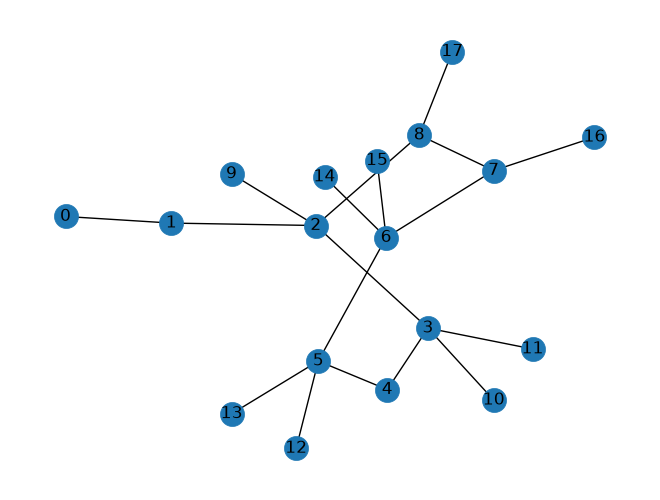

In [13]:
draw_random_networx_graph()

In [14]:
from matplotlib.animation import ArtistAnimation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import Image, display 
import seaborn as sns 



In [15]:
TRAIN_FILE = r'C:\Users\pc\Downloads\champs-scalar-coupling\train.csv'
train_df = pd.read_csv(TRAIN_FILE)
train_df.head()


,id,molecule_name,atom_index_0,atom_index_1,type,scalar_coupling_constant
0,0,dsgdb9nsd_000001,1,0,1JHC,84.8076
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.2570
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.2548
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.2543
4,4,dsgdb9nsd_000001,2,0,1JHC,84.8074


**To compare molecules fairly, we normalize each 1JHN pair: the H atom is translated to (0,0,0) and the molecule is rotated so that N lies at (1,0,0). This removes the effect of position and orientation in space, which do not influence the coupling constant, leaving only the internal geometry (distances and angles) that actually matters. It also lets us overlay molecules in the same frame and see how N's other neighbors are arranged."**

In [16]:
print(train_df.shape)                 # l-original: (4659076, 6)
print(train_df['type'].unique())      # l-original: 8 types

(4659076, 6)
['1JHC' '2JHH' '1JHN' '2JHN' '2JHC' '3JHH' '3JHC' '3JHN']


In [17]:

TEST_PATH = os.path.join(DATA_DIR, 'test.csv')
test_df = pd.read_csv(TEST_PATH)

In [18]:
print(test_df.shape)
print(test_df['type'].unique())


(2505190, 5)
['2JHC' '1JHC' '3JHH' '2JHH' '3JHC' '3JHN' '1JHN' '2JHN']


        train    test  train_%  test_%
type                                  
3JHC  1511207  811351    32.44   32.39
2JHC  1140867  613087    24.49   24.47
1JHC   709133  380968    15.22   15.21
3JHH   590529  317582    12.67   12.68
2JHH   377988  203201     8.11    8.11
3JHN   166613   90459     3.58    3.61
2JHN   119059   64647     2.56    2.58
1JHN    43680   23895     0.94    0.95


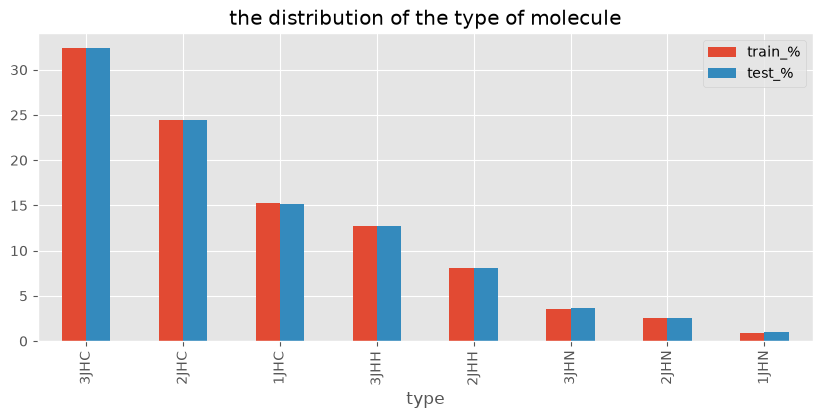

In [19]:
counts = pd.DataFrame({
    'train': train_df['type'].value_counts(),
    'test': test_df['type'].value_counts()
})
counts['train_%'] = (counts['train'] / counts['train'].sum() * 100).round(2)
counts['test_%'] = (counts['test'] / counts['test'].sum() * 100).round(2)
print(counts)
counts[['train_%', 'test_%']].plot(kind='bar', figsize=(10, 4))
plt.title('the distribution of the type of molecule')
plt.show()

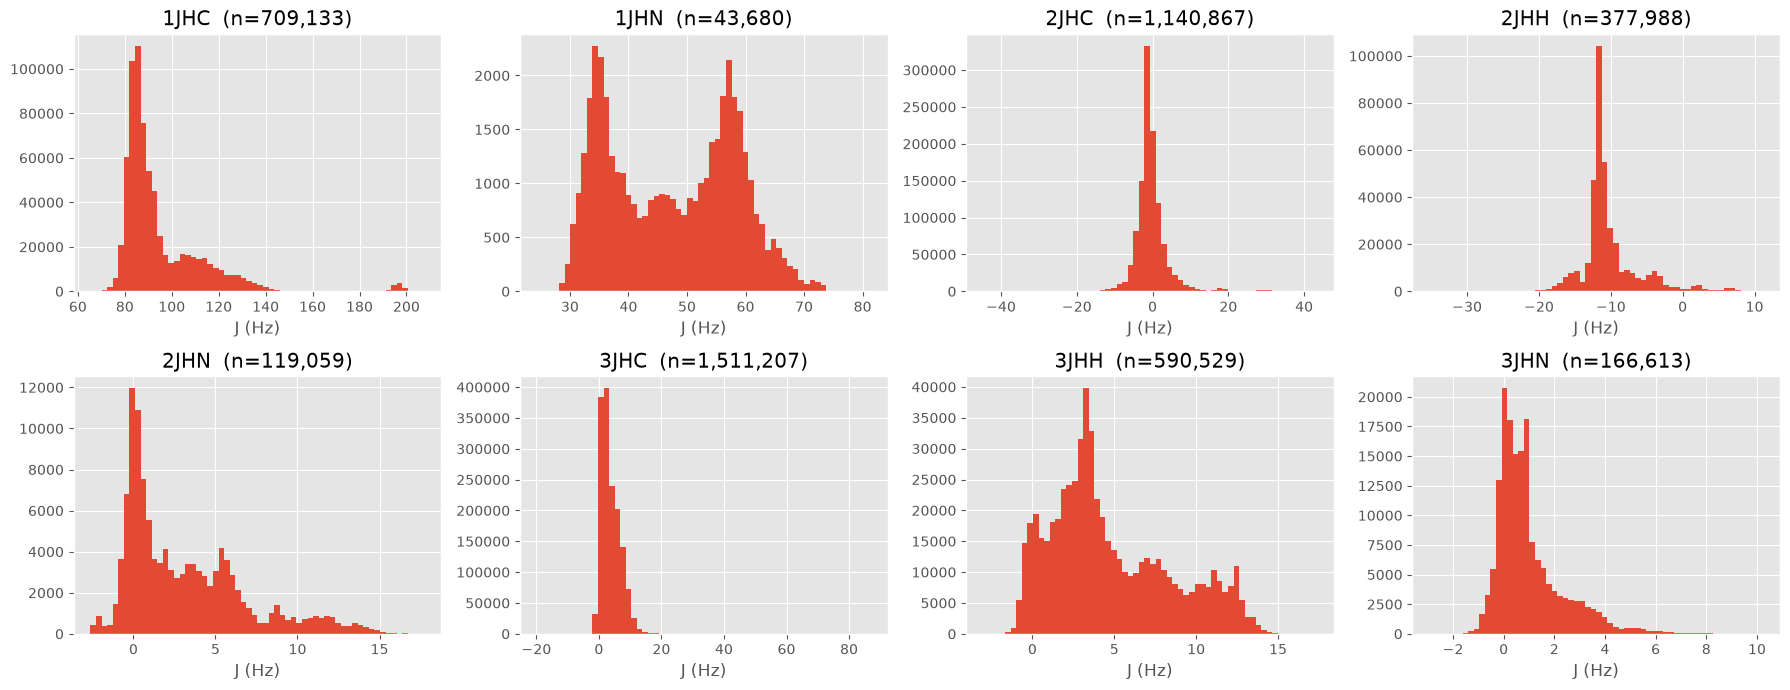

        count   mean    std    min     max
type                                      
1JHC   709133  94.97  18.29  65.35  207.71
1JHN    43680  47.49  10.90  24.32   81.40
2JHC  1140867  -0.27   4.52 -44.76   43.41
2JHH   377988 -10.28   3.98 -35.27   11.22
2JHN   119059   3.13   3.68  -2.62   17.74
3JHC  1511207   3.69   3.08 -19.89   86.96
3JHH   590529   4.77   3.71  -3.02   17.38
3JHN   166613   0.99   1.32  -2.94   10.25


In [20]:
types = sorted(train_df['type'].unique())
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for ax, t in zip(axes.ravel(), types):
    d = train_df.loc[train_df['type'] == t, 'scalar_coupling_constant']
    ax.hist(d, bins=60)
    ax.set_title(f'{t}  (n={len(d):,})')
    ax.set_xlabel('J (Hz)')

plt.tight_layout()
plt.show()

# jadwal rqmi: mean, std, min, max
print(train_df.groupby('type')['scalar_coupling_constant']
      .agg(['count', 'mean', 'std', 'min', 'max']).round(2))

In [21]:


def add_coords(df, idx):
    s = structures.rename(columns={
        'atom_index': f'atom_index_{idx}',
        'atom': f'atom_{idx}',
        'x': f'x_{idx}', 'y': f'y_{idx}', 'z': f'z_{idx}'})
    return df.merge(s, on=['molecule_name', f'atom_index_{idx}'], how='left')
    
train_df = add_coords(train_df, 0)
train_df  = add_coords(train_df, 1)
test_df = add_coords(test_df, 0)
test_df = add_coords(test_df, 1)

for df in (train_df, test_df):
    df['dist'] = np.sqrt((df['x_0'] - df['x_1'])**2 +
                         (df['y_0'] - df['y_1'])**2 +
                         (df['z_0'] - df['z_1'])**2).astype('float32')



In [22]:
train_df.head()

,id,molecule_name,atom_index_0,atom_index_1,type,scalar_coupling_constant,atom_0,x_0,y_0,z_0,atom_1,x_1,y_1,z_1,dist
0,0,dsgdb9nsd_000001,1,0,1JHC,84.8076,H,0.002150,-0.006031,0.001976,C,-0.012698,1.085804,0.008001,1.091953
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.2570,H,0.002150,-0.006031,0.001976,H,1.011731,1.463751,0.000277,1.783120
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.2548,H,0.002150,-0.006031,0.001976,H,-0.540815,1.447527,-0.876644,1.783147
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.2543,H,0.002150,-0.006031,0.001976,H,-0.523814,1.437933,0.906397,1.783157
4,4,dsgdb9nsd_000001,2,0,1JHC,84.8074,H,1.011731,1.463751,0.000277,C,-0.012698,1.085804,0.008001,1.091952


In [23]:
train_df['dist'].isna().sum().astype('float32')

np.float32(0.0)

1JHC -0.705
1JHN -0.868
2JHC 0.287
2JHH 0.529
2JHN -0.161
3JHC 0.32
3JHH 0.264
3JHN 0.272


C:\Users\pc\AppData\Local\Temp\ipykernel_11104\916620396.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g['dist'].corr(g['scalar_coupling_constant']))


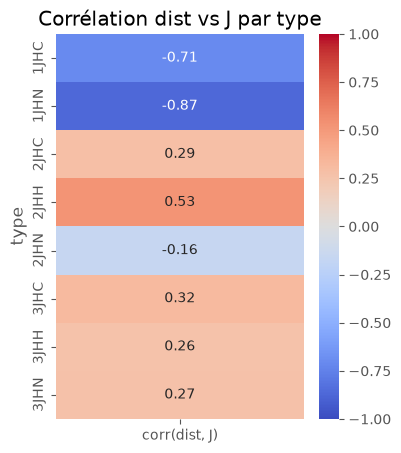

In [24]:
for t, g in train_df.groupby('type'):
    print(t, round(g['dist'].corr(g['scalar_coupling_constant']), 3))

corr_by_type = (train_df.groupby('type')
                .apply(lambda g: g['dist'].corr(g['scalar_coupling_constant']))
                .rename('corr(dist, J)')
                .to_frame())
plt.figure(figsize = (4 , 5))
sns.heatmap(corr_by_type  , annot =True , fmt = '.2f' , cmap ='coolwarm' ,vmin = -1 ,vmax =  1 ) 
plt.title('Corrélation dist vs J par type')
plt.show()



**the correlation between distance and j is so hight just for the type 1jhn or specifecly to the type 1j , for the others there is no strong relation between that feature and the others types (2j , 3j)**

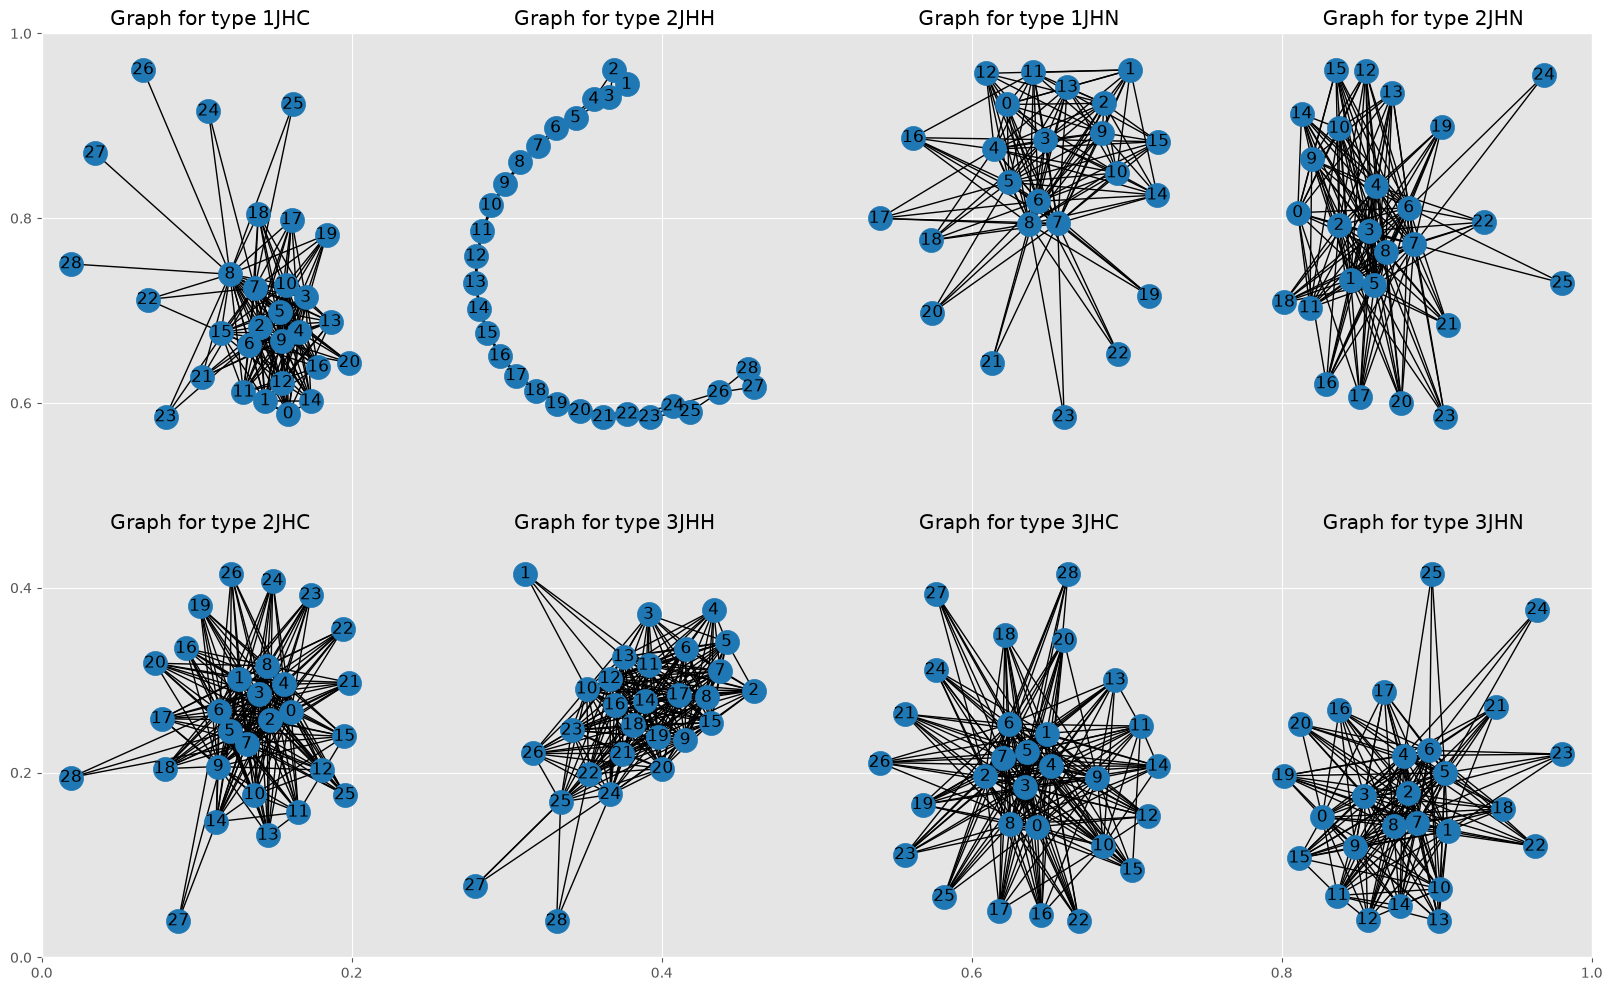

In [25]:
fig, ax = plt.subplots(figsize = (20, 12))
for i, t in enumerate(train_df['type'].unique()):
    train_type = train_df.loc[train_df['type'] == t]
    G = nx.from_pandas_edgelist(train_type, 'atom_index_0', 'atom_index_1', ['scalar_coupling_constant'])
    plt.subplot(2, 4, i + 1);
    nx.draw(G, with_labels=True);
    plt.title(f'Graph for type {t}')

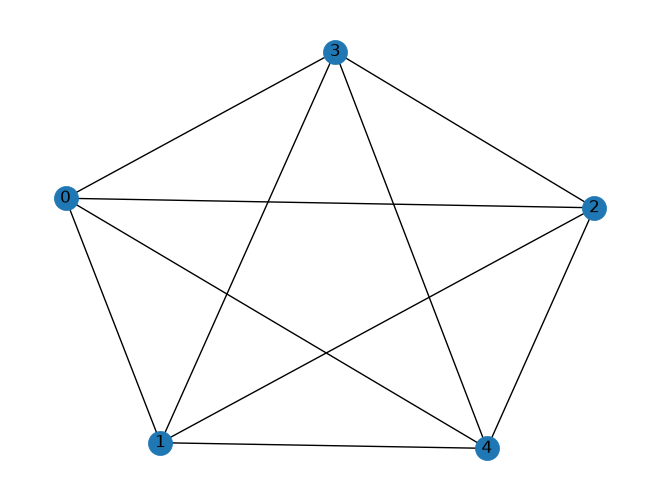

In [26]:
mol = train_df[train_df['molecule_name'] == 'dsgdb9nsd_000001']
G = nx.from_pandas_edgelist(mol, 'atom_index_0', 'atom_index_1', ['scalar_coupling_constant'])
nx.draw(G, with_labels=True)

In [27]:
COUPLING_DIR = os.path.join(DATA_DIR , 'scalar_coupling_contributions.csv')

In [28]:
scalar_coupling_constants = pd.read_csv(COUPLING_DIR)


In [29]:
DISPLAY_BONDS = False 



=== 1JHN : 10 samples (mrtbin b J) ===
            molecule_name  atom_index_0  atom_index_1   dist  scalar_coupling_constant
2293500  dsgdb9nsd_070698            12             2  1.018                    33.347
3737981  dsgdb9nsd_106803            19             8  1.019                    34.102
420138   dsgdb9nsd_014004             9             3  1.018                    35.979
115557   dsgdb9nsd_004503            11             4  1.017                    43.024
120724   dsgdb9nsd_004786            11             1  1.012                    46.226
1757406  dsgdb9nsd_057219            13             3  1.009                    51.599
4576001  dsgdb9nsd_128242            12             1  1.012                    54.667
1689208  dsgdb9nsd_054924            10             0  1.004                    57.158
3330192  dsgdb9nsd_095992             9             0  1.006                    58.359
4591680  dsgdb9nsd_129183             1             0  1.007                    63.048


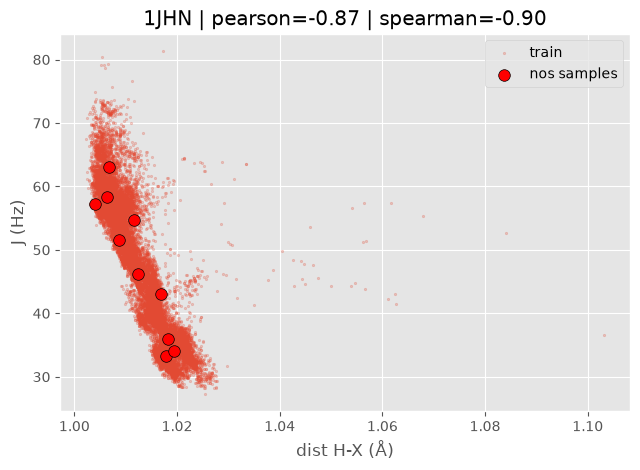

In [30]:

SELECTED_TYPES = ['1JHN']        
DIVS  = 10
SAMPLES        = 1             
DISPLAY_BONDS  = True            #
N_FRAMES       = 16              


samples_idx = {}
for t in SELECTED_TYPES:
    sub = train_df[train_df['type'] == t].copy()
    sub['bin'] = pd.qcut(sub['scalar_coupling_constant'], q=DIVS, duplicates='drop')
    samples_idx[t] = (sub.groupby('bin', observed=True)
                         .sample(SAMPLES, random_state=50)
                         .index.tolist())          # mrtbin men J sghira l kbira

for t, idx in samples_idx.items():
    print(f'\n=== {t} : {len(idx)} samples (mrtbin b J) ===')
    cols = ['molecule_name', 'atom_index_0', 'atom_index_1', 'dist', 'scalar_coupling_constant']
    print(train_df.loc[idx, cols].round(3).to_string())


fig, axes = plt.subplots(1, len(SELECTED_TYPES),
                         figsize=(6.5 * len(SELECTED_TYPES), 4.8), squeeze=False)
for ax, t in zip(axes[0], SELECTED_TYPES):
    d  = train_df[train_df['type'] == t]
    bg = d.sample(min(20000, len(d)), random_state=50)      # fond (bach ma yt9lch)
    ax.scatter(bg['dist'], bg['scalar_coupling_constant'], s=3, alpha=0.25, label='train')
    s = train_df.loc[samples_idx[t]]
    ax.scatter(s['dist'], s['scalar_coupling_constant'], s=70, color='red',
               edgecolor='black', zorder=3, label='nos samples')
    pear  = d['dist'].corr(d['scalar_coupling_constant'])
    spear = d['dist'].corr(d['scalar_coupling_constant'], method='spearman')
    ax.set_title(f'{t} | pearson={pear:.2f} | spearman={spear:.2f}')
    ax.set_xlabel('dist H-X (Å)')
    ax.set_ylabel('J (Hz)')
    ax.legend()
plt.tight_layout()
plt.show()



**Binning:** we split J (scalar_coupling_constant) into 10 quantile bins (`pd.qcut`), each bin
containing the same number of couplings, and draw one sample per bin. This gives us molecules
spread across the whole J range, to visualise how dist relates to J (feature engineering).


=== 1JHC : 10 samples ===
            molecule_name  atom_index_0  atom_index_1   dist  scalar_coupling_constant
234108   dsgdb9nsd_008373            10             0  1.096                    79.390
3988012  dsgdb9nsd_112722            20             7  1.095                    82.217
3905529  dsgdb9nsd_110730            16             6  1.100                    83.298
2915967  dsgdb9nsd_086190            24             8  1.098                    85.822
3526930  dsgdb9nsd_101516            11             0  1.093                    87.968
4022346  dsgdb9nsd_113500            17             6  1.096                    89.543
2555489  dsgdb9nsd_077299            13             3  1.091                    91.447
1431683  dsgdb9nsd_046439            10             3  1.095                    95.864
2564148  dsgdb9nsd_077530            17             7  1.094                   106.859
4565820  dsgdb9nsd_127690            13             6  1.083                   129.664


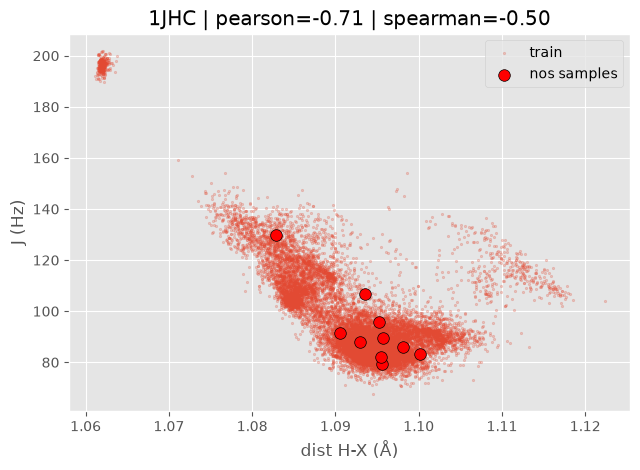

In [31]:
SELECTED_TYPES = ['1JHC']
DIVS           = 10
SAMPLES        = 1
DISPLAY_BONDS  = True
N_FRAMES       = 16

samples_idx = {}
for t in SELECTED_TYPES:
    sub = train_df[train_df['type'] == t].copy()
    sub['bin'] = pd.qcut(sub['scalar_coupling_constant'], q=DIVS, duplicates='drop')
    samples_idx[t] = (sub.groupby('bin', observed=True)
                         .sample(SAMPLES, random_state=50)
                         .index.tolist())

for t, idx in samples_idx.items():                      # <-- samples_idx
    print(f'\n=== {t} : {len(idx)} samples ===')
    cols = ['molecule_name', 'atom_index_0', 'atom_index_1', 'dist', 'scalar_coupling_constant']
    print(train_df.loc[idx, cols].round(3).to_string())

fig, axes = plt.subplots(1, len(SELECTED_TYPES),        # <-- subplots
                         figsize=(6.5 * len(SELECTED_TYPES), 4.8), squeeze=False)
for ax, t in zip(axes[0], SELECTED_TYPES):
    d  = train_df[train_df['type'] == t]
    bg = d.sample(min(20000, len(d)), random_state=50)
    ax.scatter(bg['dist'], bg['scalar_coupling_constant'], s=3, alpha=0.25, label='train')
    s = train_df.loc[samples_idx[t]]
    ax.scatter(s['dist'], s['scalar_coupling_constant'], s=70, color='red',
               edgecolor='black', zorder=3, label='nos samples')
    pear  = d['dist'].corr(d['scalar_coupling_constant'])
    spear = d['dist'].corr(d['scalar_coupling_constant'], method='spearman')
    ax.set_title(f'{t} | pearson={pear:.2f} | spearman={spear:.2f}')
    ax.set_xlabel('dist H-X (Å)')
    ax.set_ylabel('J (Hz)')
    ax.legend()
plt.tight_layout()
plt.show()

**for this visualization we assert the j value not corralted to much a the dist value , for that the spearman value is away to 1**

In [32]:

TYPE             = '1JHC'        
MODE             = 'quantile'   
SAMPLES_PER_ZONE = 3 


np_xyz = structures[['x', 'y', 'z']].values.astype('float32')
mp = {'H': 0, 'C': 1, 'O': 2, 'N': 3, 'F': 4}
np_atoms = structures['atom'].map(mp).values.astype('int8')
ss = structures.groupby('molecule_name').size().cumsum()
ssx = np.zeros(len(ss) + 1, 'int')
ssx[1:] = ss
ssx[0] = 0
np_dict = {name: k for k, name in enumerate(ss.index)}

def standardizer(mol_name, t1, t2, phi2=0, a_count=0):
    atom_df = np_atoms[ssx[np_dict[mol_name]]:ssx[np_dict[mol_name] + 1]]
    mol_df = np_xyz[ssx[np_dict[mol_name]]:ssx[np_dict[mol_name] + 1], ].copy()
    mol_df -= mol_df[t1, ]
    bond_dist = np.sqrt(mol_df[t2, ].dot(mol_df[t2, ])).astype('float32')
    mol_df /= bond_dist
 
    if mol_df[t2, 0] == 0: theta = np.sign(mol_df[t2, 2]) * np.pi / 2
    else: theta = np.arctan(mol_df[t2, 2] / mol_df[t2, 0])
    M = np.array([[np.cos(-theta), -np.sin(-theta)], [np.sin(-theta), np.cos(-theta)]])
    mol_df[:, [0, 2]] = (M.dot(mol_df[:, [0, 2]].T)).T
 
    if mol_df[t2, 0] == 0: phi = np.sign(mol_df[t2, 1]) * np.pi / 2
    else: phi = np.arctan(mol_df[t2, 1] / mol_df[t2, 0])
    if mol_df[t2, 0] < 0: phi += np.pi
    M = np.array([[np.cos(-phi), -np.sin(-phi)], [np.sin(-phi), np.cos(-phi)]])
    mol_df[:, [0, 1]] = (M.dot(mol_df[:, [0, 1]].T)).T
 
    M = np.array([[np.cos(-phi2), -np.sin(-phi2)], [np.sin(-phi2), np.cos(-phi2)]])
    mol_df[:, [1, 2]] = (M.dot(mol_df[:, [1, 2]].T)).T
 
    neighbor_types = [np.nan] * a_count
    neighbor_dists = [np.nan] * a_count
    if a_count > 0:
        dst = np.sum((mol_df - [1, 0, 0]) * (mol_df - [1, 0, 0]), axis=1)
        dst[t1] = 1e3; dst[t2] = 1e3
        idst = np.argsort(dst)
        ln = np.min((len(idst) - 2, a_count))
        neighbor_types[:ln] = atom_df[idst[:ln]]
        neighbor_dists[:ln] = dst[idst[:ln]]
 
    return (atom_df, mol_df, bond_dist, neighbor_types, neighbor_dists)
 

def animate(j, title='', display_bonds=DISPLAY_BONDS):
    atoms  = ['H', 'C', 'O', 'N', 'F']
    colors = ['white', 'lightgray', 'red', 'blue', 'green']
    sizes  = [25, 70, 60, 65, 50]
    lkeys  = [mpatches.Patch(facecolor=colors[k], label=atoms[k], edgecolor='black')
              for k in range(5)]
 
    mol_name = train_df.loc[j, 'molecule_name']
    target_1 = train_df.loc[j, 'atom_index_0']
    target_2 = train_df.loc[j, 'atom_index_1']
    constant = train_df.loc[j, 'scalar_coupling_constant']
    btype    = train_df.loc[j, 'type']
    frames = []; scl = 1.0
    fig = plt.figure(figsize=(8, 5.5))
 
    for jj, alpha in enumerate(np.linspace(0, 2 * np.pi, N_FRAMES)):
        atom_df, mol_df, dis, _, _ = standardizer(mol_name, target_1, target_2, alpha)
 
        if jj == 0:
            mxx = np.sqrt(np.max(mol_df[:, 1] ** 2 + mol_df[:, 2] ** 2))
            if btype[0] == '2':   mxx *= 1.5
            elif btype[0] == '3': mxx *= 2.0
            if mxx < 0.1: scl = 200
            else:         scl = 87. * (1 + 0.2 * (4 - mxx)) / mxx
            if display_bonds: scl /= 3.
 
        all_art = []
        if display_bonds:
            ds   = mol_df[:, None, :] - mol_df
            dist = np.sqrt(np.einsum('ijk,ijk->ij', ds, ds))
            dist = (dist < 1.65 / dis).astype(np.int8)
            for k in range(len(mol_df)):
                for kk in range(k + 1, len(mol_df)):
                    if dist[k, kk] == 1:
                        pp, = plt.plot([mol_df[k, 0], mol_df[kk, 0]],
                                       [mol_df[k, 1], mol_df[kk, 1]],
                                       color='black', zorder=-1)
                        all_art.append(pp)
 
        mol_df = np.concatenate([mol_df, atom_df.reshape((-1, 1))], axis=1)
        mol_df = mol_df[np.argsort(mol_df[:, 2], axis=0), ]
        atom_df = mol_df[:, 3].astype('int8')
 
        for k in range(len(mol_df)):
            all_art.append(plt.scatter(mol_df[k, 0], mol_df[k, 1],
                                       color=colors[atom_df[k]], edgecolor='black',
                                       s=scl * sizes[atom_df[k]]))
        plt.legend(handles=lkeys)
        pre = title if title != '' else btype
        plt.title(f'{pre} | {mol_name}\ndist = {dis:.3f} Å   |   J = {constant:.2f} Hz',
                  fontsize=13)
        plt.axis('equal')
        frames.append(all_art)
 
    ani = ArtistAnimation(fig, frames)
    fname = f'data_{btype}_{j}.gif'
    ani.save(fname, writer='pillow', fps=5)
    plt.close()
    with open(fname, 'rb') as file:
        display(Image(file.read()))

sub = train_df[train_df['type'] == TYPE]
if len(sub) == 0:
    raise ValueError(f"0 ligne to  this {TYPE}'. Types  : {sorted(train_df['type'].unique())}")
 
if MODE == 'quantile':
    bins = pd.qcut(sub['scalar_coupling_constant'], q=DIVS, duplicates='drop')
    groups = {'small j to big j ':
              sub.groupby(bins, observed=True).sample(SAMPLES, random_state=50).index.tolist()}
else:
    d, J = sub['dist'], sub['scalar_coupling_constant']
    zones = {
        'zone 1 : dist < 1.07 (cluster J ~195)'       : d < 1.07,
        'zone 2 : dist 1.075-1.09 , J > 105'           : d.between(1.075, 1.09) & (J > 105),
        'zone 3 : dist 1.09-1.10 , J < 95'             : d.between(1.09, 1.10) & (J < 95),
        'zone 4 : dist > 1.105 , J > 100 (branche)'    : (d > 1.105) & (J > 100),
    }
    groups = {}
    for name, mask in zones.items():
        z = sub[mask]
        groups[name] = (z.sample(min(SAMPLES_PER_ZONE, len(z)), random_state=50).index.tolist()
                        if len(z) else [])
 
 


######## 1JHC | small j to big j  ########
            molecule_name  atom_index_0  atom_index_1   dist  scalar_coupling_constant
234108   dsgdb9nsd_008373            10             0  1.096                    79.390
3988012  dsgdb9nsd_112722            20             7  1.095                    82.217
3905529  dsgdb9nsd_110730            16             6  1.100                    83.298
2915967  dsgdb9nsd_086190            24             8  1.098                    85.822
3526930  dsgdb9nsd_101516            11             0  1.093                    87.968
4022346  dsgdb9nsd_113500            17             6  1.096                    89.543
2555489  dsgdb9nsd_077299            13             3  1.091                    91.447
1431683  dsgdb9nsd_046439            10             3  1.095                    95.864
2564148  dsgdb9nsd_077530            17             7  1.094                   106.859
4565820  dsgdb9nsd_127690            13             6  1.083                   129.664

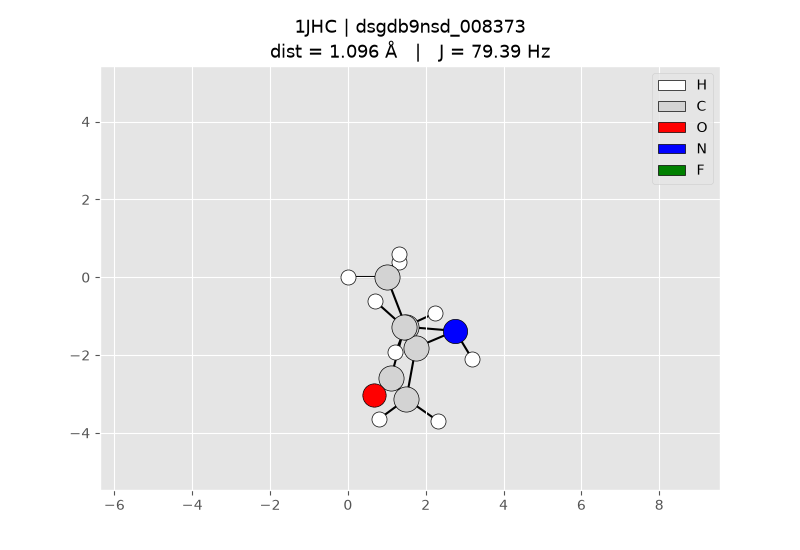

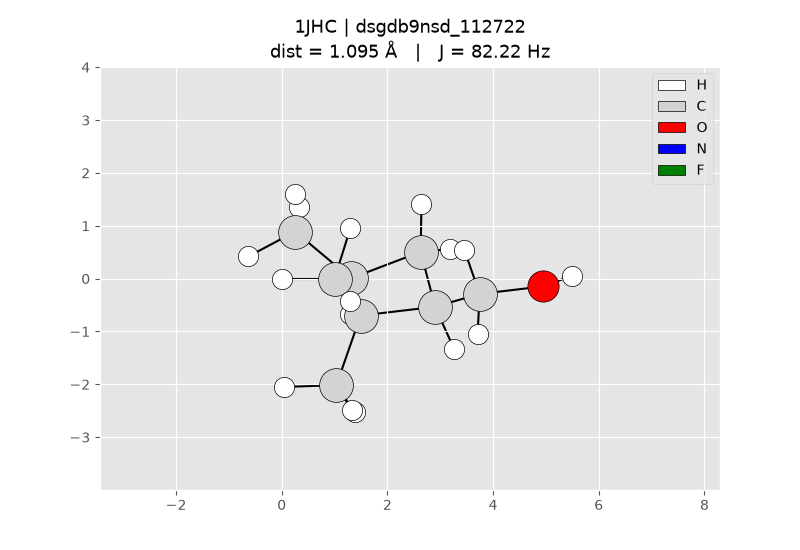

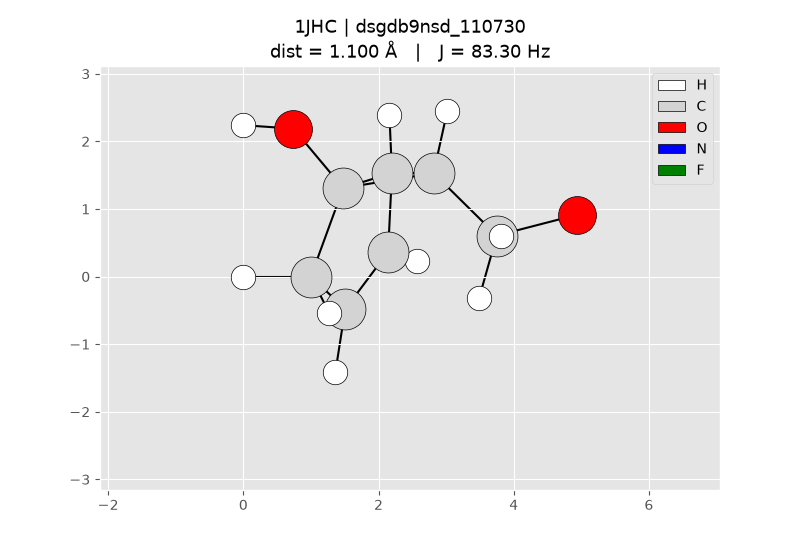

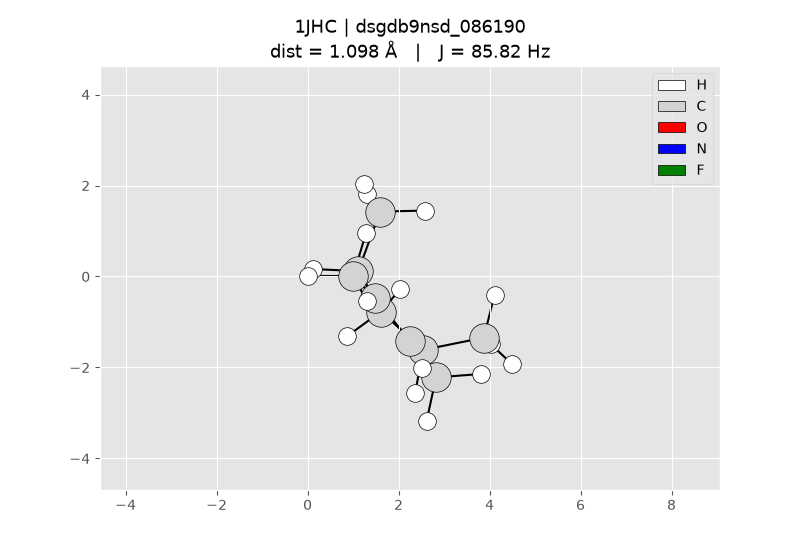

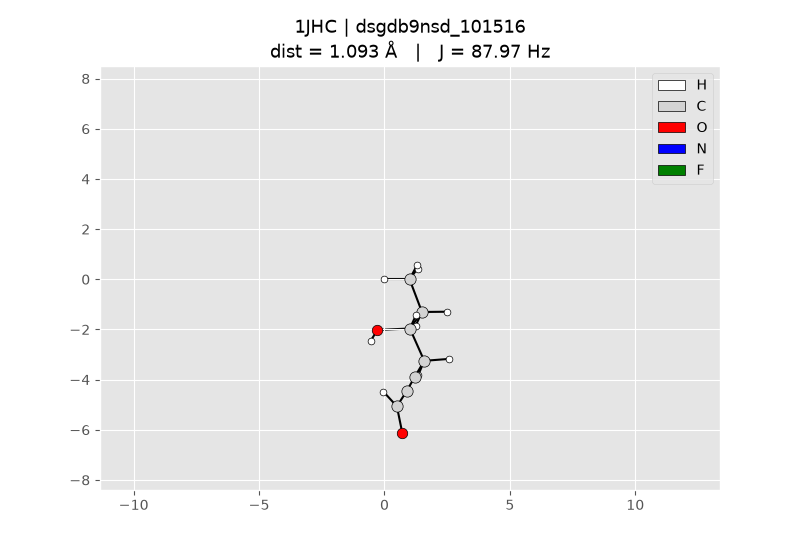

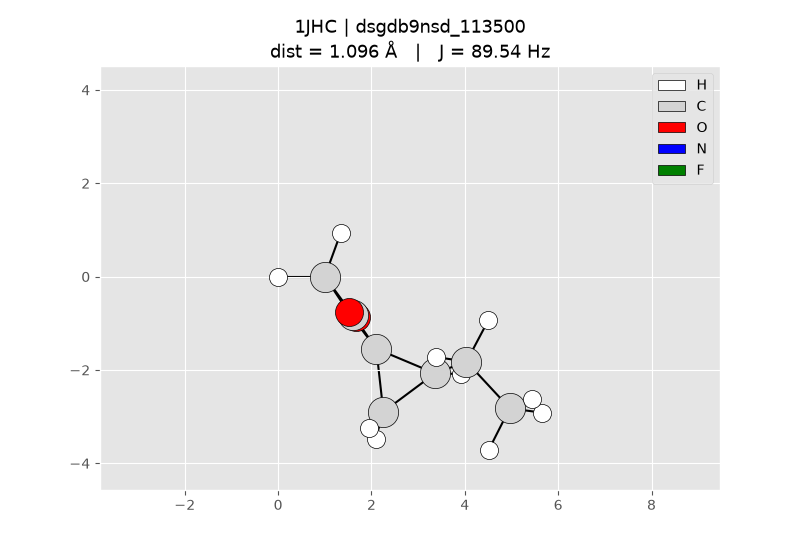

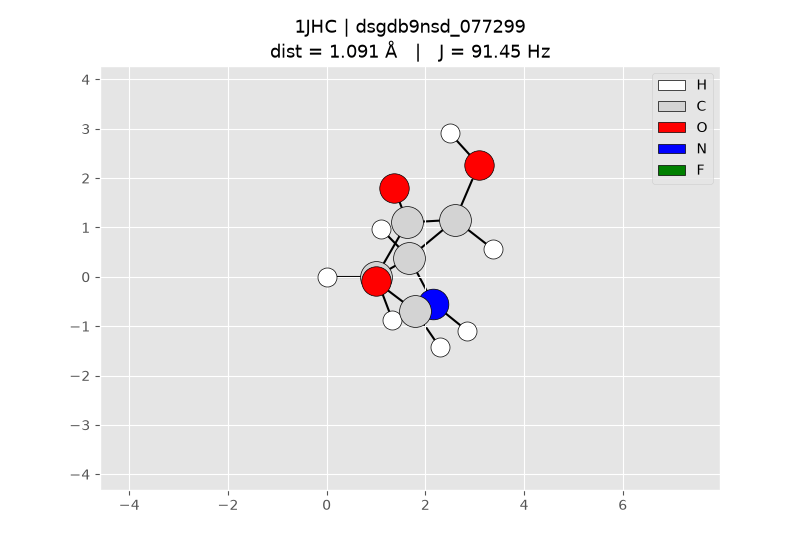

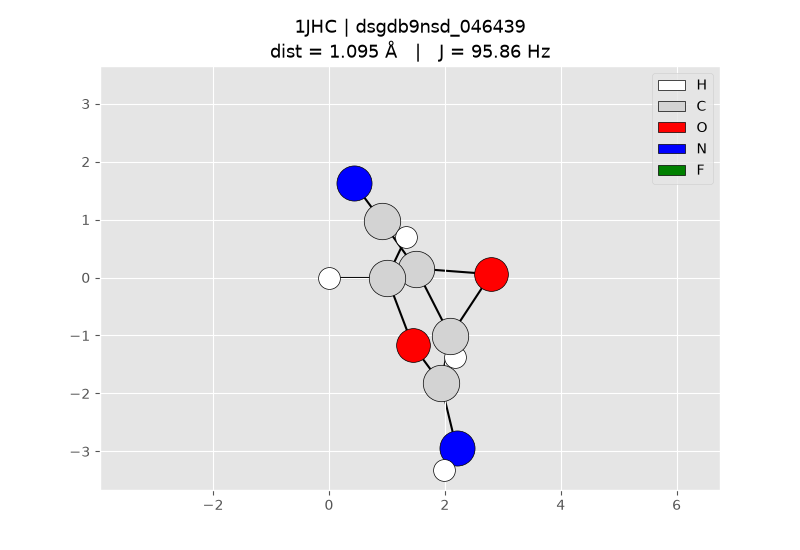

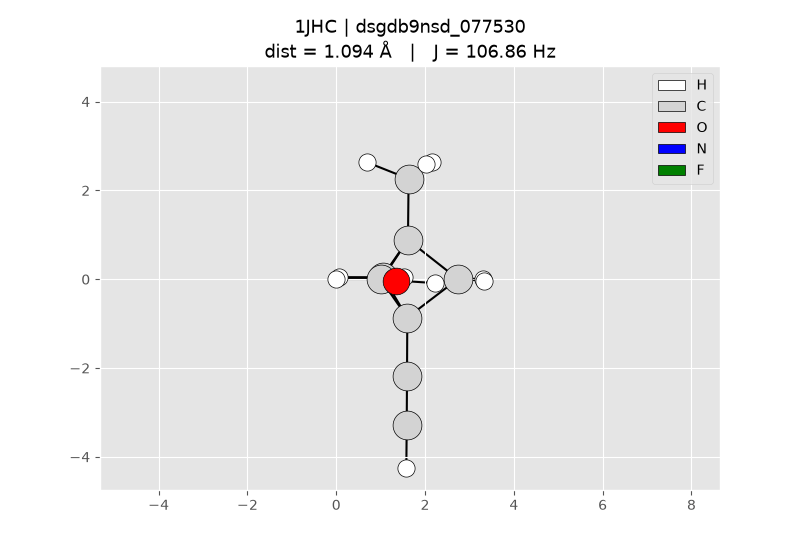

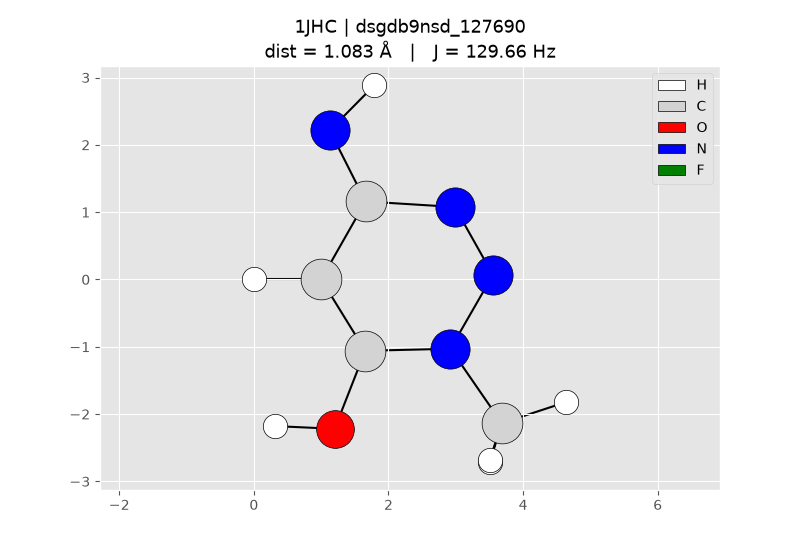

In [33]:
cols = ['molecule_name', 'atom_index_0', 'atom_index_1', 'dist', 'scalar_coupling_constant']
for name, idx in groups.items():
    print(f'\n######## {TYPE} | {name} ########')
    if not idx:
        print('(had zone farghin)')
        continue
    print(train_df.loc[idx, cols].round(3).to_string())
    for j in idx:
        animate(j)

new columns: ['a1_n_bonds', 'a1_n_H', 'a1_n_C', 'a1_n_N', 'a1_n_O', 'a1_n_F', 'a1_min_heavy_bl', 'a1_mean_bl', 'a1_mean_angle']


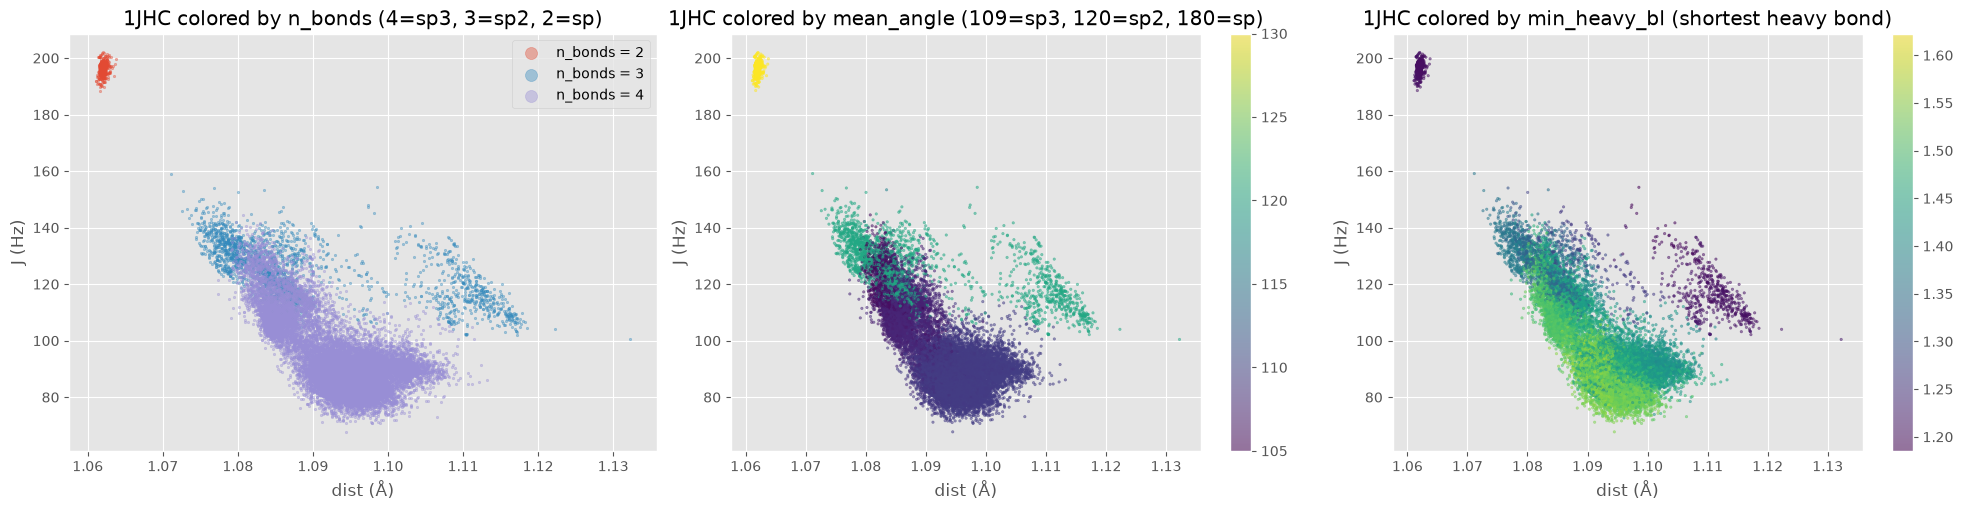

                 n   J_mean  dist_mean  corr_dist_J
a1_n_bonds                                         
2.0           9265  196.241      1.062        0.232
3.0          54222  124.694      1.090       -0.602
4.0         645646   91.024      1.094       -0.654

zone 4 : 11767 rows
a1_n_bonds
3.0    11480
4.0      287
Name: count, dtype: int64
a1_n_O    1.06
a1_n_N    0.15
a1_n_C    0.79
a1_n_H    1.01
dtype: float64
count    11767.000
mean         1.210
std          0.032
min          1.187
25%          1.203
50%          1.205
75%          1.209
max          1.565
Name: a1_min_heavy_bl, dtype: float64


In [34]:


TYPE = '1JHC'
J = 'scalar_coupling_constant'

BOND_CUTOFF = 1.65     
H_CUTOFF = 1.2         

mp = {'H': 0, 'C': 1, 'O': 2, 'N': 3, 'F': 4}
COUNT_FEATS = {'n_' + sym: code for sym, code in mp.items()}  
FEATS = ['n_bonds', 'n_H', 'n_C', 'n_N', 'n_O', 'n_F',
         'min_heavy_bl', 'mean_bl', 'mean_angle']
F = {name: np.full(len(np_xyz), np.nan, dtype=float) for name in FEATS}

for k in range(len(ssx) - 1):
    a, b = ssx[k], ssx[k + 1]
    n = b - a
    xyz = np_xyz[a:b].astype(float)
    at = np_atoms[a:b]

    diff = xyz[None, :, :] - xyz[:, None, :]
    d = np.linalg.norm(diff, axis=2)

   
    is_H = (at == 0)
    cutoff = np.where(is_H[:, None] | is_H[None, :], H_CUTOFF, BOND_CUTOFF)
    B = (d < cutoff) & (d > 0)
    nb = B.sum(1)
    F['n_bonds'][a:b] = nb

    for name, code in COUNT_FEATS.items():
        F[name][a:b] = (B & (at == code)[None, :]).sum(1)

    dh = np.where(B & (at != 0)[None, :], d, np.inf)
    mn = dh.min(1)
    mn[np.isinf(mn)] = np.nan
    F['min_heavy_bl'][a:b] = mn

    F['mean_bl'][a:b] = np.where(nb > 0, (d * B).sum(1) / np.maximum(nb, 1), np.nan)

    u = diff / np.where(d > 0, d, 1.0)[:, :, None]
    cos = np.clip(np.einsum('ijc,ikc->ijk', u, u), -1, 1)
    M = B[:, :, None] & B[:, None, :] & np.triu(np.ones((n, n), bool), 1)[None, :, :]
    ang = np.degrees(np.arccos(np.where(M, cos, 0.0)))
    cnt = M.sum((1, 2))
    F['mean_angle'][a:b] = np.where(cnt > 0, (ang * M).sum((1, 2)) / np.maximum(cnt, 1), np.nan)


def add_atom_feats(df, col='atom_index_1', prefix='a1_'):
    rows = ssx[df['molecule_name'].map(np_dict).values.astype(int)] + df[col].values
    for name, arr in F.items():
        df[prefix + name] = arr[rows]
    return df

train_df = add_atom_feats(train_df)
test_df = add_atom_feats(test_df)
print('new columns:', [c for c in train_df.columns if c.startswith('a1_')])

sub = train_df[train_df['type'] == TYPE].copy()
bg = sub.sample(min(30000, len(sub)), random_state=50)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))

for v, g in bg.groupby('a1_n_bonds'):
    axes[0].scatter(g['dist'], g[J], s=3, alpha=0.4, label=f'n_bonds = {int(v)}')
axes[0].legend(markerscale=5)
axes[0].set_title(f'{TYPE} colored by n_bonds (4=sp3, 3=sp2, 2=sp)')

for ax, col, ttl, vmin, vmax in [
        (axes[1], 'a1_mean_angle',   'mean_angle (109=sp3, 120=sp2, 180=sp)', 105, 130),
        (axes[2], 'a1_min_heavy_bl', 'min_heavy_bl (shortest heavy bond)',    None, None)]:
    sc = ax.scatter(bg['dist'], bg[J], c=bg[col], s=3, alpha=0.5,
                    cmap='viridis', vmin=vmin, vmax=vmax)     # vmin/vmax: sp (180) saturates, sp2/sp3 become visible
    plt.colorbar(sc, ax=ax)
    ax.set_title(f'{TYPE} colored by {ttl}')

for ax in axes:
    ax.set_xlabel('dist (Å)')
    ax.set_ylabel('J (Hz)')
plt.tight_layout()
plt.show()

res = (sub.groupby('a1_n_bonds')
          .agg(n=(J, 'size'),
               J_mean=(J, 'mean'),
               dist_mean=('dist', 'mean'))
          .join(sub.groupby('a1_n_bonds')
                   .apply(lambda g: g['dist'].corr(g[J]), include_groups=False)
                   .rename('corr_dist_J'))
          .round(3))
print(res)


z4 = sub[(sub['dist'] > 1.105) & (sub[J] > 100)]
print(f'\nzone 4 : {len(z4)} rows')
print(z4['a1_n_bonds'].value_counts().sort_index())
print(z4[['a1_n_O', 'a1_n_N', 'a1_n_C', 'a1_n_H']].mean().round(2))
print(z4['a1_min_heavy_bl'].describe().round(3))

# Conclusion: 1JHC and the hybridisation of the carbon (Step B)

## Question
`dist` alone explains 1JHC only partly (Pearson -0.71, Spearman -0.50): the same C-H distance
can give very different J values. Hypothesis: the bonding environment of the carbon
(its hybridisation) explains the rest.

## Method
- `structures.csv` only gives atom types and xyz coordinates, with no connectivity. Bonds are inferred from distances:
  cutoff 1.65 Å for heavy-heavy bonds and 1.2 Å for any bond involving H
  (this avoids fake H-H bonds in molecules like NH3 or H2O).
- For the carbon of each coupling (`atom_index_1`) we computed: `n_bonds`, neighbour counts
  (`n_H`, `n_C`, `n_O`, `n_N`, `n_F`), `min_heavy_bl` (shortest bond to a non-H atom),
  `mean_bl` and `mean_angle` (mean angle between its bonds).
- We coloured the `dist` vs J scatter with these features.

## Findings
| Zone | dist (Å) | J (Hz) | n_bonds | mean_angle | min_heavy_bl (Å) | Interpretation |
|---|---|---|---|---|---|---|
| Small cluster | ~1.062 | ~195 | 2 | ~180° | ~1.20 | sp carbon (C≡C) |
| Upper-left band | 1.075-1.09 | 105-150 | 3 | ~120° | ~1.30-1.40 | sp2 carbon (C=C, aromatic) |
| Right-hand branch | 1.105-1.12 | 105-135 | 3 | ~120° | ~1.20 | sp2 carbon with a short bond, compatible with C=O (aldehyde) |
| Dense lower mass | 1.09-1.10 | 70-110 | 4 | ~109° | ~1.45-1.55 | sp3 carbon (C-C, C-O) |

## Conclusions
1. **The hybridisation of the carbon drives J**: fewer neighbours, a larger mean angle and a shorter
   heavy bond all go with a larger J (sp > sp2 > sp3). The three features split the scatter into the same zones.
2. **`dist` and J are correlated mostly because both depend on the hybridisation**
   (s-character). This is why `dist` alone cannot separate the groups; the right-hand branch has the
   longest C-H bonds but a high J.
3. `n_bonds`, `mean_angle` and `min_heavy_bl` are strong candidate features, but they are not
   independent (all are proxies of hybridisation), so some redundancy is expected.
4. A spread remains inside the sp3 mass (J from 70 to ~130 at the same `dist`):
   it should depend on what the carbon is attached to, hence the neighbour counts
   (`n_O`, `n_N`, `n_C`).

## Limits
- These conclusions are visual. They are quantified in the next step by comparing a model
  trained with `dist` only against `dist` + features (log-MAE).
- The C=O interpretation of the right-hand branch is consistent with the plots (3 neighbours, ~120°,
  bond ~1.20 Å) but still has to be confirmed with `n_O` in that zone.
- Bonds come from fixed distance cutoffs; covalent radii would be more accurate.

## Next steps
1. LightGBM on 1JHC: `dist` only vs `dist` + features (log-MAE, split by molecule).
2. Repeat for 1JHN (same code, `atom_index_1` is N).
3. 2J and 3J: angle H-X-Y and dihedral angle (cos phi, cos 2phi), since `dist` is not enough there.

In [35]:
train_df.head(20)

    

,id,molecule_name,atom_index_0,atom_index_1,type,scalar_coupling_constant,atom_0,x_0,y_0,z_0,...,dist,a1_n_bonds,a1_n_H,a1_n_C,a1_n_N,a1_n_O,a1_n_F,a1_min_heavy_bl,a1_mean_bl,a1_mean_angle
0,0,dsgdb9nsd_000001,1,0,1JHC,84.80760,H,0.002150,-0.006031,0.001976,...,1.091953,4.0,4.0,0.0,0.0,0.0,0.0,NaN,1.091950,109.471221
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.25700,H,0.002150,-0.006031,0.001976,...,1.783120,1.0,0.0,1.0,0.0,0.0,0.0,1.091952,1.091952,NaN
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.25480,H,0.002150,-0.006031,0.001976,...,1.783147,1.0,0.0,1.0,0.0,0.0,0.0,1.091946,1.091946,NaN
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.25430,H,0.002150,-0.006031,0.001976,...,1.783157,1.0,0.0,1.0,0.0,0.0,0.0,1.091948,1.091948,NaN
4,4,dsgdb9nsd_000001,2,0,1JHC,84.80740,H,1.011731,1.463751,0.000277,...,1.091952,4.0,4.0,0.0,0.0,0.0,0.0,NaN,1.091950,109.471221
5,5,dsgdb9nsd_000001,2,3,2JHH,-11.25410,H,1.011731,1.463751,0.000277,...,1.783158,1.0,0.0,1.0,0.0,0.0,0.0,1.091946,1.091946,NaN
6,6,dsgdb9nsd_000001,2,4,2JHH,-11.25480,H,1.011731,1.463751,0.000277,...,1.783148,1.0,0.0,1.0,0.0,0.0,0.0,1.091948,1.091948,NaN
7,7,dsgdb9nsd_000001,3,0,1JHC,84.80930,H,-0.540815,1.447527,-0.876644,...,1.091946,4.0,4.0,0.0,0.0,0.0,0.0,NaN,1.091950,109.471221
8,8,dsgdb9nsd_000001,3,4,2JHH,-11.25430,H,-0.540815,1.447527,-0.876644,...,1.783148,1.0,0.0,1.0,0.0,0.0,0.0,1.091948,1.091948,NaN
9,9,dsgdb9nsd_000001,4,0,1JHC,84.80950,H,-0.523814,1.437933,0.906397,...,1.091948,4.0,4.0,0.0,0.0,0.0,0.0,NaN,1.091950,109.471221


# Conclusion: EDA and feature-engineering plan (CHAMPS scalar coupling)

## 1. Goal
Predict `scalar_coupling_constant` (J, Hz) between two atoms of a molecule from its 3D
structure. There are 8 coupling types (1JHC, 1JHN, 2JHH, 2JHC, 2JHN, 3JHH, 3JHC, 3JHN).
So far the notebook covers EDA only; no model has been trained yet.

## 2. What we did
- Loaded structures / train / test and compared the type distributions.
- Plotted the J distribution for each type.
- Built `dist` (Euclidean distance between the two atoms) and measured its correlation with J per type.
- Built `standardizer` (H at the origin, second atom at (1,0,0)) and animated molecules.

## 3. Findings
| Type | corr(dist, J) | Reading |
|---|---|---|
| 1JHN | -0.87 | strong, clean, monotonic (Spearman -0.90) |
| 1JHC | -0.71 | misleading (Spearman only -0.50): 3-4 distinct zones |
| 2JHH | 0.53 | moderate |
| 2JHC, 3JHC, 3JHH, 3JHN | 0.26 to 0.32 | weak |
| 2JHN | -0.16 | almost none |

- 1J couplings (one bond): the distance is the bond length, so `dist` is a strong feature.
  For 1JHN it is almost enough on its own.
- 2J and 3J couplings (two or three bonds): `dist` alone is weak. J depends others features


## 4. 1JHC: hypothesis (to be verified)
The same C-H distance can give very different J values. Hypothesis: the hybridisation
of the carbon (number of neighbours: sp = 2, sp2 = 3, sp3 = 4) controls both
the bond length and J through its s-character (sp > sp2 > sp3).
- ~1.06 A, J ~195: sp zone (small cluster)
- 1.075-1.09 A, J 105-140: sp2 zone
- 1.09-1.10 A, J 80-107: sp3 zone (dense region)
- > 1.105 A, J 105-135: right-hand branch, cause still unknown




In [64]:
TYPES    = ['1JHC' , '1JHN']  
MAX_ROWS = None             
J        = 'scalar_coupling_constant'
FEATS    = ['n_bonds', 'n_H', 'n_C', 'n_N', 'n_O', 'n_F',
            'min_heavy_bl', 'mean_bl', 'mean_angle']
feat_cols = ['a1_' + f for f in FEATS]
experiments = {'dist only': ['dist'],
               'dist + features': ['dist'] + feat_cols}

In [65]:

from sklearn.model_selection import GroupShuffleSplit
import lightgbm as lgb
from sklearn.inspection import permutation_importance

def make_model():
    return lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.1, num_leaves=64,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.9,
                             random_state=50, n_jobs=-1, verbose=-1)

def fit(model, X_train, y_train, X_val, y_val):
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
              eval_metric='l1', callbacks=[lgb.early_stopping(100, verbose=False)])

def get_importance(model, X_val, y_val, cols):
    if hasattr(model, 'booster_'):
        imp = model.booster_.feature_importance(importance_type='gain')
    else:
        idx = np.random.RandomState(50).choice(len(X_val), min(5000, len(X_val)), replace=False)
        imp = permutation_importance(model, X_val.iloc[idx], y_val.iloc[idx], n_repeats=3,
                                     random_state=50, scoring='neg_mean_absolute_error').importances_mean
        imp = np.clip(imp, 0, None)
    return pd.Series(100 * imp / imp.sum(), index=cols).sort_values()

def run(TYPE):
    sub = train_df[train_df['type'] == TYPE]
    if MAX_ROWS and len(sub) > MAX_ROWS:
        sub = sub.sample(MAX_ROWS, random_state=50)
    sub = sub.reset_index(drop=True)

    y = sub[J].values 
    tr, va = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=50).split(sub, groups=sub['molecule_name']))
    
    out = {}
    for name, cols in experiments.items():
        X = sub[cols]
        model = make_model()
        fit(model, X.iloc[tr], y[tr], X.iloc[va], y[va])
        pred = model.predict(X.iloc[va])
        mae = np.mean(np.abs(y[va] - pred))
        out[name] = dict(model=model, pred=pred, mae=mae, log_mae=np.log(mae), cols=cols)
        print(f'{TYPE} | {name:16s} | MAE = {mae:7.3f} Hz | log-MAE = {np.log(mae):6.3f}')
    return sub, va, y, out

def plot_results(TYPE, sub, va, y, out):
    A, B = out['dist only'], out['dist + features']
    yv = y[va]
    rng = np.random.RandomState(50)
    samp = rng.choice(len(va), min(15000, len(va)), replace=False)
    gain = (1 - B['mae'] / A['mae']) * 100

    fig, axes = plt.subplots(2, 3, figsize=(19, 10))
    fig.suptitle(f'{TYPE} : LightGBM  |  validation = {len(va):,} couplings (split by molecule)  |  '
                 f'MAE {gain:.0f}% lower with features', fontsize=14)
    
    ax = axes[0, 0]
    names = list(out)
    maes = [out[n]['mae'] for n in names]
    bars = ax.bar(names, maes, color=['#9aa0a6', '#7a5cd6'])
    for b_, n in zip(bars, names):
        ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height(),
                f"{out[n]['mae']:.2f} Hz\nlog-MAE {out[n]['log_mae']:.2f}",
                ha='center', va='bottom')
    ax.set_ylim(0, max(maes) * 1.3)
    ax.set_ylabel('MAE (Hz)')
    ax.set_title('Validation error')
    
    ax = axes[0, 1]
    g = pd.DataFrame({'nb': sub.loc[va, 'a1_n_bonds'].values,
                      'A': np.abs(yv - A['pred']), 'B': np.abs(yv - B['pred'])})
    e = g.groupby('nb').agg(n=('A', 'size'), A=('A', 'mean'), B=('B', 'mean'))
    e = e[e['n'] >= 50]
    x = np.arange(len(e)); w = 0.38
    ax.bar(x - w / 2, e['A'], w, label='dist only', color='#9aa0a6')
    ax.bar(x + w / 2, e['B'], w, label='dist + features', color='#7a5cd6')
    ax.set_xticks(x)
    ax.set_xticklabels([f'n_bonds={int(i)}\n(n={n:,})' for i, n in zip(e.index, e['n'])])
    ax.set_ylabel('MAE (Hz)')
    ax.set_title('Error by number of bonds of the atom')
    ax.legend()
    ax = axes[0, 2]
    imp = get_importance(B['model'], sub.loc[va, B['cols']], yv, B['cols'])
    ax.barh(imp.index, imp.values, color='#7a5cd6')
    ax.set_xlabel('importance (%)')
    ax.set_title('Feature importance (dist + features)')
    lo, hi = yv.min(), yv.max()
    for ax, M, title in [(axes[1, 0], A, 'dist only'), (axes[1, 1], B, 'dist + features')]:
        ax.scatter(yv[samp], M['pred'][samp], s=2, alpha=0.3)
        ax.plot([lo, hi], [lo, hi], color='red', lw=1)
        ax.set_xlabel('actual J (Hz)'); ax.set_ylabel('predicted J (Hz)')
        ax.set_title(f"{title} | MAE = {M['mae']:.2f}")
    ax = axes[1, 2]
    rA, rB = yv - A['pred'], yv - B['pred']
    lim = np.percentile(np.abs(np.r_[rA, rB]), 99)
    bins = np.linspace(-lim, lim, 80)
    ax.hist(rA, bins=bins, alpha=0.55, label='dist only', color='#9aa0a6')
    ax.hist(rB, bins=bins, alpha=0.55, label='dist + features', color='#7a5cd6')
    ax.set_xlabel('error = actual - predicted (Hz)')
    ax.set_title('Error distribution')
    ax.legend()
 
    plt.tight_layout()
    plt.show()



c:\Users\pc\my_env\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


1JHC | dist only        | MAE =   5.257 Hz | log-MAE =  1.660


c:\Users\pc\my_env\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


1JHC | dist + features  | MAE =   1.933 Hz | log-MAE =  0.659


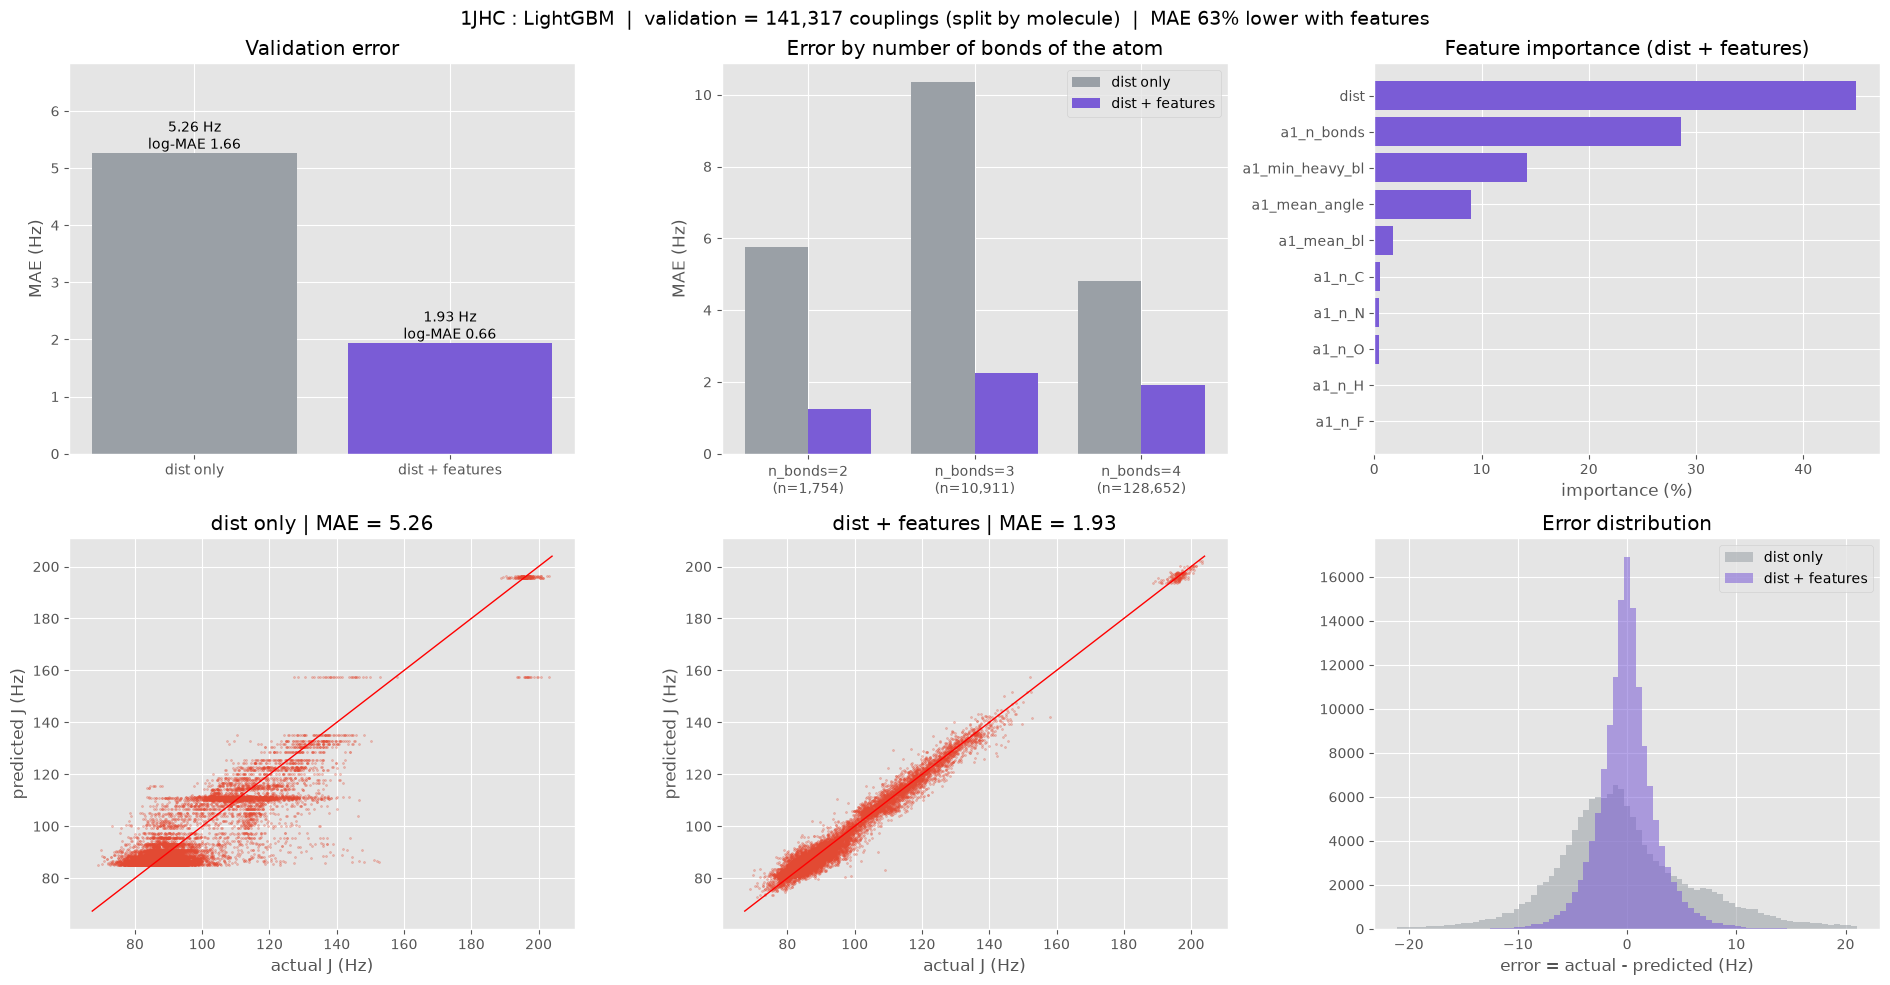

c:\Users\pc\my_env\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


1JHN | dist only        | MAE =   3.004 Hz | log-MAE =  1.100


c:\Users\pc\my_env\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


1JHN | dist + features  | MAE =   0.809 Hz | log-MAE = -0.212


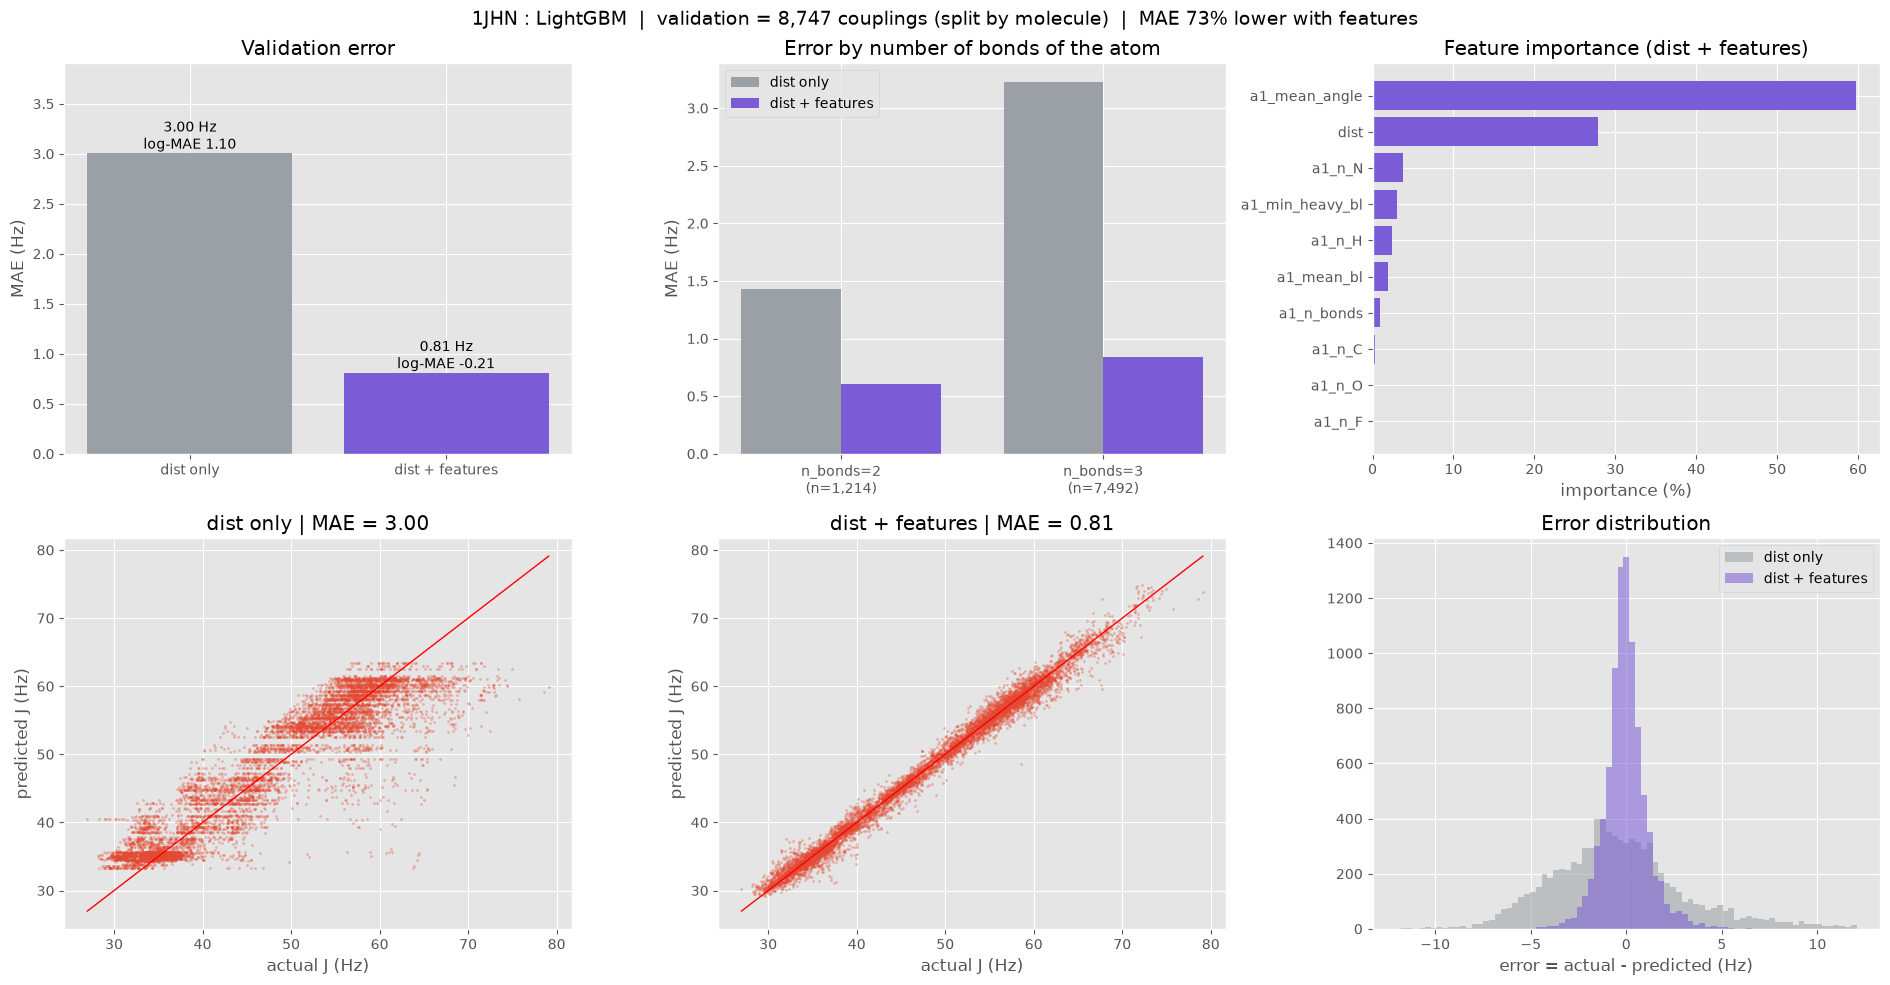


       MAE dist only  MAE + features  log-MAE dist only  log-MAE + features  gain log-MAE
type                                                                                    
1JHC          5.257           1.933               1.66               0.659         1.001
1JHN          3.004           0.809               1.10              -0.212         1.312

Moyenne log-MAE : dist only = 1.380 | + features = 0.223


In [66]:
rows = []
for T in TYPES:
    sub_T, va_T, y_T, out_T = run(T)
    plot_results(T, sub_T, va_T, y_T, out_T)
    rows.append({'type': T,
                 'MAE dist only': out_T['dist only']['mae'],
                 'MAE + features': out_T['dist + features']['mae'],
                 'log-MAE dist only': out_T['dist only']['log_mae'],
                 'log-MAE + features': out_T['dist + features']['log_mae']})
 
summary = pd.DataFrame(rows).set_index('type')
summary['gain log-MAE'] = summary['log-MAE dist only'] - summary['log-MAE + features']
print('\n', summary.round(3).to_string())
print(f"\nMoyenne log-MAE : dist only = {summary['log-MAE dist only'].mean():.3f} | "
      f"+ features = {summary['log-MAE + features'].mean():.3f}")

LightGBM, `dist` only vs `dist` + atom features (full data, split by molecule)

| Type | MAE dist only | MAE + features | log-MAE dist only | log-MAE + features |
|---|---|---|---|---|
| 1JHC | 5.26 Hz | **1.93 Hz** (-63%) | 1.66 | **0.66** |
| 1JHN | 3.00 Hz | **0.81 Hz** (-73%) | 1.10 | **-0.21** |
| mean | | | 1.38 | **0.23** |

we found The bonding-environment features cut the error by 63% (1JHC) and 73% (1JHN), This supports the hypothesis that the hybridisation of the heavy atom explains
most of the variance that `dist` alone cannot.
Without features the model predicts horizontal stripes (same prediction for many different J); with them the points follow the diagonal.
- 1JHC: `dist` 45%, `n_bonds` 29%, `min_heavy_bl` 14%, `mean_angle` 9%.The neighbour counts (`n_C`, `n_N`, `n_O`, `n_F`) are close to 0%.
- 1JHN: `mean_angle` 60%, `dist` 28%. The nitrogen hybridisation is more continuous, (pyramidal amine vs planar amide), which `mean_angle` captures better than `n_bonds`.
- 1JHC remaining error is mostly sp3 carbons (91% of the data, MAE about 1.9 Hz).


**Features are correlated (all proxies of hybridisation), so importances are not additive. An ablation is needed to quantify each feature.**


**found a features for reforcing my predictor model for that type of BONd 1j**


In [36]:

test_df



,id,molecule_name,atom_index_0,atom_index_1,type,atom_0,x_0,y_0,z_0,atom_1,...,dist,a1_n_bonds,a1_n_H,a1_n_C,a1_n_N,a1_n_O,a1_n_F,a1_min_heavy_bl,a1_mean_bl,a1_mean_angle
0,4659076,dsgdb9nsd_000004,2,0,2JHC,H,-1.661639,0.000000,1.000000,C,...,2.261178,2.0,1.0,1.0,0.0,0.0,0.0,1.199079,1.130589,180.000000
1,4659077,dsgdb9nsd_000004,2,1,1JHC,H,-1.661639,0.000000,1.000000,C,...,1.062099,2.0,1.0,1.0,0.0,0.0,0.0,1.199079,1.130589,180.000000
2,4659078,dsgdb9nsd_000004,2,3,3JHH,H,-1.661639,0.000000,1.000000,H,...,3.323277,1.0,0.0,1.0,0.0,0.0,0.0,1.062099,1.062099,NaN
3,4659079,dsgdb9nsd_000004,3,0,1JHC,H,1.661639,0.000000,1.000000,C,...,1.062099,2.0,1.0,1.0,0.0,0.0,0.0,1.199079,1.130589,180.000000
4,4659080,dsgdb9nsd_000004,3,1,2JHC,H,1.661639,0.000000,1.000000,C,...,2.261178,2.0,1.0,1.0,0.0,0.0,0.0,1.199079,1.130589,180.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505185,7164261,dsgdb9nsd_133885,15,3,2JHC,H,1.260745,-1.246754,-1.906767,C,...,2.307978,4.0,1.0,3.0,0.0,0.0,0.0,1.503272,1.410252,106.266360
2505186,7164262,dsgdb9nsd_133885,15,4,2JHC,H,1.260745,-1.246754,-1.906767,C,...,2.314978,4.0,1.0,2.0,0.0,1.0,0.0,1.432254,1.397071,107.686676
2505187,7164263,dsgdb9nsd_133885,15,6,3JHC,H,1.260745,-1.246754,-1.906767,C,...,3.343889,4.0,0.0,3.0,0.0,1.0,0.0,1.410384,1.503354,106.014043
2505188,7164264,dsgdb9nsd_133885,15,7,2JHC,H,1.260745,-1.246754,-1.906767,C,...,2.315573,4.0,1.0,2.0,1.0,0.0,0.0,1.503272,1.421439,107.951277


In [37]:
def build_summary(df : pd.DataFrame) -> pd.DataFrame:
    rows = []
    for column in df.columns:
        rows.append({
            'Column Name': column
             , 'Data Type': df[column].dtype
            , 'Missing Values': df[column].isnull().sum() , 
            'missing pct ' : df[column].isnull().sum() / len(df) * 100 , 
            'nunique': int(df[column].nunique()),
                      'sample_values': ','.join(df[column].dropna().astype(str).unique()[:4]),
                  })




    return pd.DataFrame(rows)


In [38]:
TARGET = ['scalar_coupling_constant']

eda_cols = [c for c in train_df.columns if c not in TARGET ]
eda_summary = build_summary(train_df[eda_cols])
print(eda_summary)
     


        Column Name Data Type  Missing Values  missing pct   nunique  \
0                id     int64               0      0.000000  4659076   
1     molecule_name    object               0      0.000000    85012   
2      atom_index_0     int64               0      0.000000       28   
3      atom_index_1     int64               0      0.000000       29   
4              type    object               0      0.000000        8   
5            atom_0    object               0      0.000000        1   
6               x_0   float64               0      0.000000   785804   
7               y_0   float64               0      0.000000   785809   
8               z_0   float64               0      0.000000   785804   
9            atom_1    object               0      0.000000        3   
10              x_1   float64               0      0.000000  1183002   
11              y_1   float64               0      0.000000  1183015   
12              z_1   float64               0      0.000000  118

In [39]:
eda_cols_test = [c for c in test_df.columns]
eda_summary_test = build_summary(test_df[eda_cols_test])
print(eda_summary_test)



        Column Name Data Type  Missing Values  missing pct   nunique  \
0                id     int64               0      0.000000  2505190   
1     molecule_name    object               0      0.000000    45777   
2      atom_index_0     int64               0      0.000000       29   
3      atom_index_1     int64               0      0.000000       29   
4              type    object               0      0.000000        8   
5            atom_0    object               0      0.000000        1   
6               x_0   float64               0      0.000000   422666   
7               y_0   float64               0      0.000000   422666   
8               z_0   float64               0      0.000000   422664   
9            atom_1    object               0      0.000000        3   
10              x_1   float64               0      0.000000   636723   
11              y_1   float64               0      0.000000   636718   
12              z_1   float64               0      0.000000   63

In [40]:
df_scalar_coupling_contributions = pd.read_csv(os.path.join(DATA_DIR, 'scalar_coupling_contributions.csv'))

df_scalar_coupling_contributions.head(3)

,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.27201
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.43360
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.43387


In [41]:
test_features = pd.concat([df_scalar_coupling_contributions, test_df], ignore_index=True)
test_features 

,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso,id,atom_0,...,dist,a1_n_bonds,a1_n_H,a1_n_C,a1_n_N,a1_n_O,a1_n_F,a1_min_heavy_bl,a1_mean_bl,a1_mean_angle
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.272010,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.433600,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.433870,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,dsgdb9nsd_000001,1,4,2JHH,-11.0319,0.352934,2.85855,-3.433930,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,dsgdb9nsd_000001,2,0,1JHC,83.0222,0.254585,1.25861,0.272013,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7164261,dsgdb9nsd_133885,15,3,2JHC,NaN,NaN,NaN,NaN,7164261.0,H,...,2.307978,4.0,1.0,3.0,0.0,0.0,0.0,1.503272,1.410252,106.266360
7164262,dsgdb9nsd_133885,15,4,2JHC,NaN,NaN,NaN,NaN,7164262.0,H,...,2.314978,4.0,1.0,2.0,0.0,1.0,0.0,1.432254,1.397071,107.686676
7164263,dsgdb9nsd_133885,15,6,3JHC,NaN,NaN,NaN,NaN,7164263.0,H,...,3.343889,4.0,0.0,3.0,0.0,1.0,0.0,1.410384,1.503354,106.014043
7164264,dsgdb9nsd_133885,15,7,2JHC,NaN,NaN,NaN,NaN,7164264.0,H,...,2.315573,4.0,1.0,2.0,1.0,0.0,0.0,1.503272,1.421439,107.951277
